# Audio Processing

This notebook turns the raw `.wav` recordings into the timbre descriptors used on our study.
The output of this notebook, `descriptors_v2.csv`, is the dataset read by `data_visualization.ipynb` and `permanova.ipynb`.

In [304]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# Essentia

Audio processing and descriptor extraction rely on [Essentia](https://essentia.upf.edu/), an open-source library and tools for audio and music analysis, description and synthesis.

In [305]:
import essentia.standard as es

## Initial processing

The sample rate, frame size, and hop size below are fixed for the whole pipeline, so every measurement is computed with the same time-frequency resolution.

In [306]:
sr = 48000
# sample rate from audios_v1 is 96 kHz, so the loader will resample to 48 kHz
# sample rate from audios_v2 is already 48 kHz
frame_size = 1024 # approx: 23.2 ms
hop_size = 256 # 5.8 ms

Audio is loaded as mono and resampled to the common rate defined above.

In [307]:
def loadMonoAudio(audio_path):
    
    audio = es.MonoLoader(
        filename=audio_path,
        sampleRate=sr,
        resampleQuality= 0, # from essentia docs: "0 for best quality, 4 for fast linear approximation"
    )()

    return audio

In [308]:
# processes the .wav files into numeric arrays and stores them

from collections import defaultdict

audio_folder = '../data/audios_v2/'
processed_audios = defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(dict)))) # creates an empty five level dictionary to store the structure [harp][note][material][method][rep]

for audio in os.listdir(audio_folder):

    audio_name = os.path.splitext(audio)[0]

    name_parts = audio_name.split('_')
    harp = name_parts[0].strip()[4:] # only get Bb or C
    material = name_parts[1].strip().lower()
    method = name_parts[2].strip().lower()
    note = name_parts[3].strip()
    repetition = name_parts[4].strip().replace(' ', '')[3:] # just get the number of repetition

    file_path = audio_folder + audio
    processed_audios[harp][note][material][method][repetition] = loadMonoAudio(file_path)

In [309]:
def getProcessedAudios(harp, note, material, method, repetition):
    y = processed_audios[harp][note][material][method][repetition]
    return y

## STFT

The process known as the Short-Time Fourier Transform (STFT) is given by

$$ X(m,k) = \sum_{n=0}^{N-1} x(n + mH)\,w(n)\, e^{-j\frac{2\pi}{N}kn}, $$

where $w(n)$ is a windowing function of length $N$ (`frame_size`) and $H$ is the `hop_size`. The STFT is computed here with a Hamming window, giving the magnitude spectrum $|X(m,k)|$ used by the spectral extraction functions.

In [310]:
sustain_start = 2.0
sustain_end = 5.0 

In [311]:
def calcSTFT(audio, window='hamming'):

    window = es.Windowing(  # from essentia docs: "results in a Hamming window similar to the default SciPy implementation"
        type=window,
        size = frame_size,
        constantsDecimals=2,
        normalized=False,
        zeroPhase=False
    )
    
    spectrum = es.Spectrum() # from essentia docs: "FFT() would return the complex FFT, here we just want the magnitude spectrum"

    magnitudes = []

    for frame in es.FrameGenerator(audio, frameSize=frame_size, hopSize=hop_size):
        mag = spectrum(window(frame)) 
        magnitudes.append(mag)

    return magnitudes

In [312]:
def sustainedNote(magnitudes):

    frame_times = np.arange(len(magnitudes)) * hop_size / sr

    sel_magnitudes = []

    # we just evaluated the spectral analysis of 3 seconds of the recordings, discarding frames outside that interval
    for i, t in enumerate(frame_times): 
        if sustain_start <= t <= sustain_end:
            sel_magnitudes.append(magnitudes[i])
        else:
            sel_magnitudes.append(np.nan)

    return sel_magnitudes

The fundamental frequency ($f_0$) defines the perceived pitch of a sound.
It is computed here to confirm that each recording actually corresponds to the note indicated in its filename, and that bend notes reached the intended target pitch.

In [313]:
def calcMeanF0(magnitudes):
    
    magnitudes = sustainedNote(magnitudes)
    
    pitch_extractor = es.PitchYinFFT(frameSize=frame_size, sampleRate=sr) # from essentia docs: "This algorithm estimates the fundamental frequency given the spectrum of a monophonic music signal."
    pitches = []
    
    for mag in magnitudes:
        if mag is np.nan:
            pitches.append(np.nan)
        else:
            pitch, confidence = pitch_extractor(mag)
            
            # counts only pitches with detection confidence above 70%
            if confidence > 0.7:
                pitches.append(pitch)
                

    mean_f0 = np.nanmean(pitches)

    return pitches, mean_f0

## Descriptors

Spectral centroid and attack time were selected because they are the main timbre descriptors. They are the descriptors most consistently linked to how listeners perceive timbre.
This section defines the functions used to compute both, applied to every recording.

### Spectral Centroid

The spectral centroid represents the center of gravity of the frequency spectrum, a measure perceptually associated with the brightness of a sound. It is defined as the amplitude-weighted mean frequency:


$$ \bar{f} = \frac{\sum_{i=1}^{N} f_i \cdot A_i}{\sum_{i=1}^{N} A_i},$$


where $f_i$ are the frequency components and $A_i$ their respective amplitudes. A higher value of $\bar{f}$ indicates that spectral energy is concentrated at higher frequencies.

In [314]:
def calcMeanCentroid(magnitudes):
    
    magnitudes = sustainedNote(magnitudes)

    centroid = es.Centroid(range=sr/2) # essentia docs: "For a spectral centroid [hz], frequency range should be equal to samplerate/2"
    centroids = []

    for mag in magnitudes:
        if mag is np.nan:
            centroids.append(np.nan)
        else:
            centroids.append(centroid(mag)) 

    mean_centroid = np.nanmean(centroids)

    return centroids, mean_centroid


def calcMedianCentroid(magnitudes):

    centroid = es.Centroid(range=sr/2)
    centroids = []

    for mag in magnitudes:
        centroids.append(centroid(mag)) 

    median_centroid = np.median(centroids)
    return centroids, median_centroid


### Log-AttackTime

In this study, attack time is defined as the time interval for the signal envelope to rise from 20% to 80% of its peak value. The log-attack-time is defined as

$$\text{LAT} = \log_{10} (t_{end} - t_{st}),$$

where $t_{st}$ and $t_{end}$ are the start and the end of attack time, respectively.

In [315]:
def getEnvelope(audio):
    envelope = es.Envelope( #essentia docs: "This algorithm computes the envelope of a signal by applying a non-symmetric lowpass filter on a signal"
        sampleRate=sr,
    )(audio)
    return envelope

def getLogAttackTime(envelope):
    log_attack = es.LogAttackTime(
        sampleRate=sr,
        startAttackThreshold=0.2,
        stopAttackThreshold=0.8
    )(envelope)
    return log_attack

def calcLogAttackTime(audio):

    envelope = getEnvelope(audio)

    log_attack = getLogAttackTime(envelope) # log_attack returns a tuple with 3 values

    attack_time = 10 ** log_attack[0] # converts to time in seconds

    return log_attack[0], attack_time

## Graphs

### Spectrogram

The magnitude output of the STFT can be visualized as a spectrogram, a two-dimensional representation with time on the horizontal axis and frequency on the vertical axis, where amplitude is encoded as color intensity.

In [316]:
def plotSpectrum(audio, magnitudes, mean_centroids, median_centroids):
    S = np.array(magnitudes)
    S = S / S.max()
    S_db = 20 * np.log10(S + 1e-8)

    mean_times = np.arange(len(mean_centroids)) * (hop_size / sr)
    audio_times = np.arange(len(audio)) / sr

    fig = plt.figure(figsize=(6, 7))
    gs = GridSpec(2, 2, width_ratios=[1, 0.04], height_ratios=[3, 1], hspace=0.08, wspace=0.05)
    ax1 = fig.add_subplot(gs[0, 0])               # spectrogram
    ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)   # waveform
    cax = fig.add_subplot(gs[0, 1])               # colorbar

    # spectrogram
    im = ax1.imshow(S_db.T, origin='lower', aspect='auto',
                    extent=[0, mean_times[-1], 0, sr / 2], cmap='magma',
                    vmin=-80, vmax=np.max(S_db))
    ax1.set_ylim(0, 20000)
    ax1.set_ylabel('Frequency (Hz)')
    ax1.tick_params(labelbottom=False)

    ax1.plot(mean_times, median_centroids, color='grey', linewidth=2.5,
             label='Spectral centroid')
    ax1.plot(mean_times, mean_centroids, color='white', linewidth=2.5,
             label='Spectral centroid (selected interval)')

    fig.colorbar(im, cax=cax, label='Amplitude (dB)')

    # waveform
    audio_plot = audio / np.max(np.abs(audio))   # normaliza pelo pico
    ax2.plot(audio_times, audio_plot, color='purple', alpha=0.7, linewidth=0.6)
    ax2.set_ylim(-1.05, 1.05)
    ax2.set_ylabel('Normalized amplitude')
    ax2.set_xlabel('Time (s)')

    plt.show()

### Attack Envelope

This representation plots the normalized envelope amplitude over time, with the signals aligned at the onset of their attack phase. It visually highlights the attack duration—measured between the 20% and 80% thresholds for natural blow, natural draw, and bend notes.

In [317]:
def plotAttack(audio_blow, audio_draw, audio_bend):
    curves = [('Natural, blow', audio_blow, 'tab:orange'),
              ('Natural, draw', audio_draw, 'tab:green'),
              ('Bend', audio_bend, 'tab:blue')]

    fig = plt.figure(figsize=(3.4, 2.4))
    ax = fig.add_subplot(111)

    longest = 0
    for label, audio, color in curves:
        # getattack (same calculation as calcLogAttackTime)
        envelope = getEnvelope(audio)
        _, t_st, t_end = getLogAttackTime(envelope)

        ref = envelope.max()                                       # 100% = envelope peak
        audio_times = (np.arange(len(audio)) / sr - t_st) * 1000   # time from attack start (ms)
        attack_ms = (t_end - t_st) * 1000

        ax.plot(audio_times, envelope / ref, color=color, linewidth=1.2, label=f'{label}: {attack_ms:.0f} ms')

        # start and end of the attack on each curve
        i_st, i_end = int(t_st * sr), min(int(t_end * sr), len(envelope) - 1)
        ax.plot([0, attack_ms], [envelope[i_st] / ref, envelope[i_end] / ref],'o', color=color, markersize=3)
        longest = max(longest, attack_ms)

    ax.axhline(0.2, color='grey', linestyle=':', linewidth=0.8)
    ax.axhline(0.8, color='grey', linestyle=':', linewidth=0.8)
    ax.set_xlim(-0.1 * longest, 1.6 * longest)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Envelope')
    ax.set_xlabel('Time from attack start (ms)')
    ax.legend(fontsize=6, loc='lower right')

    plt.show()

## Amplitude, Power and SNR Metrics

Recording levels are reported in dBFS (decibels relative to digital full scale), since no absolute acoustic calibration was performed. Because the interface gain was fixed during the whole session, these values are comparable across recordings.

The metrics below are computed from two segments of each recording: the **sustained interval** (2-5 s, the same window used for the spectral centroid) and a **noise segment** taken before the attack.

### Level Conversion

The root mean square (RMS) amplitude of a signal $x$ with $N$ samples is

$$ \text{RMS} = \sqrt{\frac{1}{N}\sum_{n=0}^{N-1} x(n)^2}, $$

and any linear amplitude $A$ is converted to dBFS as

$$ L = 20 \log_{10}(A). $$

A floor of $10^{-12}$ is applied before the logarithm to avoid $\log(0)$ on silent segments.

In [318]:
def toDb(x):
    return 20 * np.log10(max(x, 1e-12))   # amplitude to dB re full scale

def calcRms(audio):
    return es.RMS()(audio)

### Signal Segmentation

Level and noise metrics are computed on two segments of each recording. 

The sustained segment is the 2-5 s interval, the same window used for the spectral centroid, so level and timbre refer to the same part of the note. 

The noise segment goes from the start of the recording until 0.15 s before the attack start $t_{st}$ (from the log-attack-time algorithm). This segment captures the background noise of the room and of the recording chain.

In [319]:
def getSustainedSegment(audio):
    trimmer = es.Trimmer(startTime=sustain_start, endTime=sustain_end)
    return trimmer(audio)

# from the start of the recording until shortly before the attack
def getNoiseSegment(audio):
    noise_margin = 0.15 # kept clear before the attack when selecting the noise segment

    envelope = getEnvelope(audio)
    _, t_st, _ = getLogAttackTime(envelope)

    n_end = t_st - noise_margin
    
    if n_end > 0:
        trimmer = es.Trimmer(startTime=0.0, endTime=n_end)
        return trimmer(audio)
    return np.array([], dtype=np.float32)

### Level and Noise Descriptors

Four descriptors are extracted, all in dBFS. The peak level (`peak_dbfs`) is the largest absolute sample of the whole recording and is used to verify that no clipping occurred. The sustained level (`rms_sus_dbfs`) and the noise floor (`rms_noise_dbfs`) are the RMS levels of the sustained and noise segments, respectively. The signal-to-noise ratio (`snr_db`) subtracts the noise power from the sustained segment, which also contains it:

$$ \text{SNR} = 10 \log_{10}\left(\frac{P_{sus} - P_{noise}}{P_{noise}}\right), $$

where $P_{sus}$ and $P_{noise}$ are the squared RMS values of the sustained and noise segments. A floor of $10^{-20}$ keeps the numerator positive.

In [320]:
def calcPeakDb(audio):
    peak, _ = es.MinMax(type='max')(np.abs(audio))
    return toDb(peak)

def calcSustainRmsDb(audio):
    seg = getSustainedSegment(audio)
    return toDb(calcRms(seg))

def calcNoiseRmsDb(audio):
    seg = getNoiseSegment(audio)
    return toDb(calcRms(seg))

def calcSNR(audio):
    seg = getSustainedSegment(audio)
    noise = getNoiseSegment(audio)
        
    p_noise = calcRms(noise) ** 2
    p_signal = max(calcRms(seg) ** 2 - p_noise, 1e-20)
    
    return 10 * np.log10(p_signal / p_noise)

# Dataset

In [321]:
# create the dataframe
data = {
    'harp':[],
    'note': [],
    'f0': [],
    'material': [],
    'method': [],
    'rep': [],
    'centroid': [],
    'logattacktime': [],
    'atk_time': [],
    'peak_dbfs': [], 
    'rms_sus_dbfs': [], 
    'rms_noise_dbfs': [], 
    'snr_db': [],
}

rows = []

for harp, notes in processed_audios.items():
    for note, materials in notes.items():
        for material, methods in materials.items():
            for method, repetitions in methods.items():
                for repetition, audio_data in repetitions.items():

                    audio = getProcessedAudios(harp, note, material, method, repetition)
                    stft = calcSTFT(audio)

                    _, mean_f0 = calcMeanF0(stft)
                    
                    # compute timbre descriptors
                    _, mean_centroid = calcMeanCentroid(stft)
                    logattacktime, attack_time = calcLogAttackTime(audio)

                    # builds the dataset row
                    data['harp'].append(harp)
                    data['note'].append(note)
                    data['f0'].append(mean_f0)
                    data['material'].append(material)
                    data['method'].append(method)
                    data['rep'].append(repetition)
                    data['centroid'].append(mean_centroid)
                    data['logattacktime'].append(logattacktime)
                    data['atk_time'].append(attack_time * 1000) # convert to milisseconds

                    data['peak_dbfs'].append(calcPeakDb(audio))
                    data['rms_sus_dbfs'].append(calcSustainRmsDb(audio))
                    data['rms_noise_dbfs'].append(calcNoiseRmsDb(audio))
                    data['snr_db'].append(calcSNR(audio))

In [322]:
import pandas as pd

df = pd.DataFrame(data)
df.to_csv('../data/descriptors_v2.csv', index=False)

pd.set_option('display.max_rows', None)
df

,harp,note,f0,material,method,rep,centroid,logattacktime,atk_time,peak_dbfs,rms_sus_dbfs,rms_noise_dbfs,snr_db
0,Bb,A4,444.204053,wood,natural,1,6220.307132,-0.945164,113.458269,-8.730417,-18.956659,-55.806116,36.848560
1,Bb,A4,444.386402,wood,natural,2,6422.600591,-0.970701,106.979135,-7.531633,-19.131261,-55.456306,36.324034
2,Bb,A4,444.159059,wood,natural,3,6026.273239,-0.613352,243.583374,-7.833236,-18.543801,-56.084033,37.539467
3,Bb,A4,444.513295,wood,natural,4,6376.058053,-0.732388,185.187582,-8.675553,-20.088289,-55.855388,35.765948
4,Bb,A4,444.647125,wood,natural,5,6491.929599,-0.749529,178.020779,-8.825511,-20.130221,-56.407849,36.276604
5,Bb,A4,444.746079,abs,natural,1,6075.585657,-0.984273,103.687525,-10.302138,-20.357253,-52.794136,32.434405
6,Bb,A4,444.967121,abs,natural,2,6103.607262,-1.178268,66.333294,-8.143596,-20.805932,-49.858835,29.047499
7,Bb,A4,445.010441,abs,natural,3,6422.342622,-1.101686,79.124985,-9.133879,-22.151260,-47.271110,25.106470
8,Bb,A4,444.572193,abs,natural,4,6184.933366,-0.992021,101.854208,-8.498883,-19.849944,-49.489974,29.635309
9,Bb,A4,444.739517,abs,natural,5,6198.625336,-1.037493,91.729175,-8.726369,-20.115539,-50.156428,30.036585


### Graph Preview

**The evenly spaced horizontal bands visible below correspond to the note harmonics, occurring at integer multiples of $f_0$.**

Overlaid on the spectrogram is the spectral centroid trajectory: the grey line tracks the centroid across the entire recording, while the white line restricts it to 3 seconds sustained interval used for the centroid extraction.

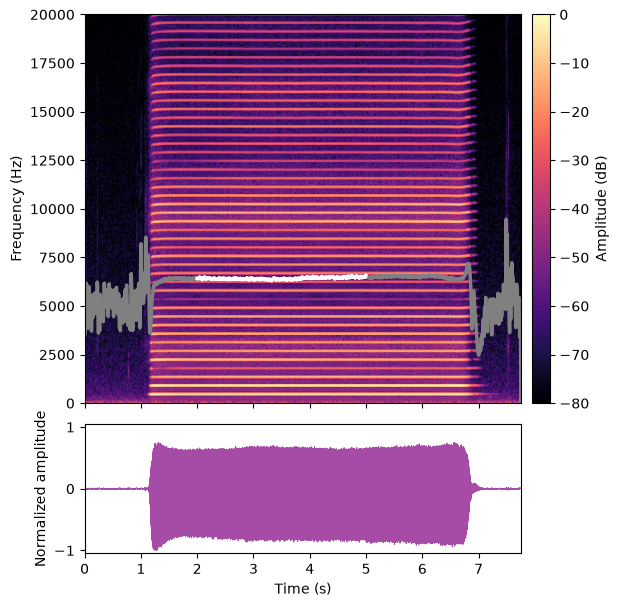

In [323]:
harp = 'Bb'
note = 'A4'
material = 'wood'
method = 'natural'
repetition = '2'

audio_nat = getProcessedAudios(harp, note, material, method, repetition)
stft = calcSTFT(audio_nat)

mean_centroids, mean_centroid = calcMeanCentroid(stft)
median_centroids, median_centroid = calcMedianCentroid(stft)
logattacktime, attack_time = calcLogAttackTime(audio_nat)

plotSpectrum(audio_nat, stft, mean_centroids, median_centroids)


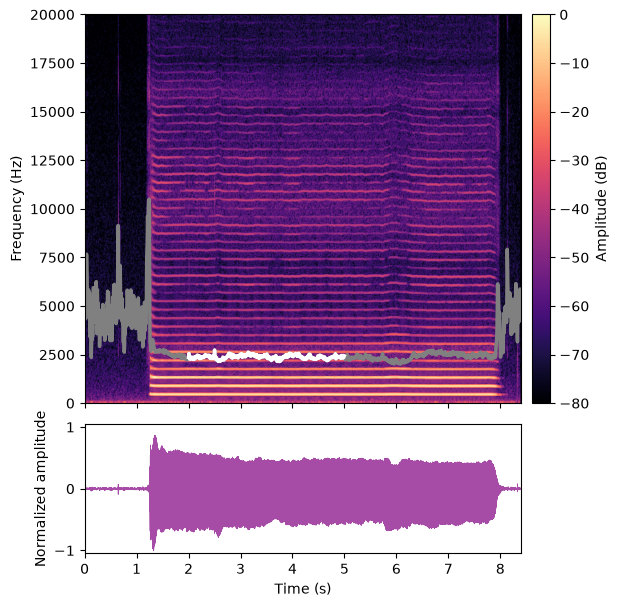

In [324]:
harp = 'C'
note = 'A4'
material = 'wood'
method = 'bend'
repetition = '5'

audio_bend = getProcessedAudios(harp, note, material, method, repetition)
stft = calcSTFT(audio_bend)

mean_centroids, mean_centroid = calcMeanCentroid(stft)
median_centroids, median_centroid = calcMedianCentroid(stft)
logattacktime, attack_time = calcLogAttackTime(audio_bend)

plotSpectrum(audio_bend, stft, mean_centroids, median_centroids)

blow G4 C wood 2 249 ms
draw F4 Bb wood 2 205 ms
bend E4 Bb abs 3 53 ms


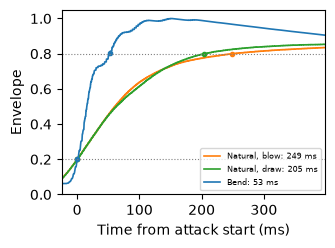

In [325]:
def getRepresentative(notes, method):
    # recording whose attack time is closest to the median of the condition
    s = df[df.note.isin(notes) & (df.method == method)]
    r = s.loc[(s.atk_time - s.atk_time.median()).abs().idxmin()]
    audio = getProcessedAudios(r.harp, r.note, r.material, r.method, str(int(r.rep)))
    return audio, r

audio_blow, r_blow = getRepresentative(['E4', 'G4'], 'natural')
audio_draw, r_draw = getRepresentative(['F4', 'A4'], 'natural')
audio_bend, r_bend = getRepresentative(['E4', 'G4', 'F4', 'A4'], 'bend')

for name, r in [('blow', r_blow), ('draw', r_draw), ('bend', r_bend)]:
    print(name, r.note, r.harp, r.material, int(r.rep), round(r.atk_time), 'ms')

plotAttack(audio_blow, audio_draw, audio_bend)
